# Figure 1 — Sensitivity analysis (1% convergence threshold)

**Phase 4 exploratory reanalysis.** All three figures are drawn inline from the original Phase 3 CSV data; no retraining and no changes to source datasets. Convergence is retrospectively defined as training classification error **≤1% for two consecutive recorded epochs**. This differs from Phase 3’s 0.1% criterion, and should not be presented as the original criterion.


## Figure 1(a) — Inception training loss

Training cross-entropy versus optimization steps for true labels, random labels, shuffled pixels, random pixels, and Gaussian input. Colors/markers follow the original paper. A trailing 100-step mean reduces minibatch noise; `SMOOTHING_STEPS = 1` plots raw loss.

Reading: C:\Users\ASUS\Documents\GitHub\advanced-ml-paper-reproductions\paper1-generalization\results\figure1
True labels: 25,000 steps; last step 25,000
Random labels: 25,000 steps; last step 25,000
Shuffled pixels: 25,000 steps; last step 25,000
Random pixels: 25,000 steps; last step 25,000
Gaussian: 25,000 steps; last step 25,000


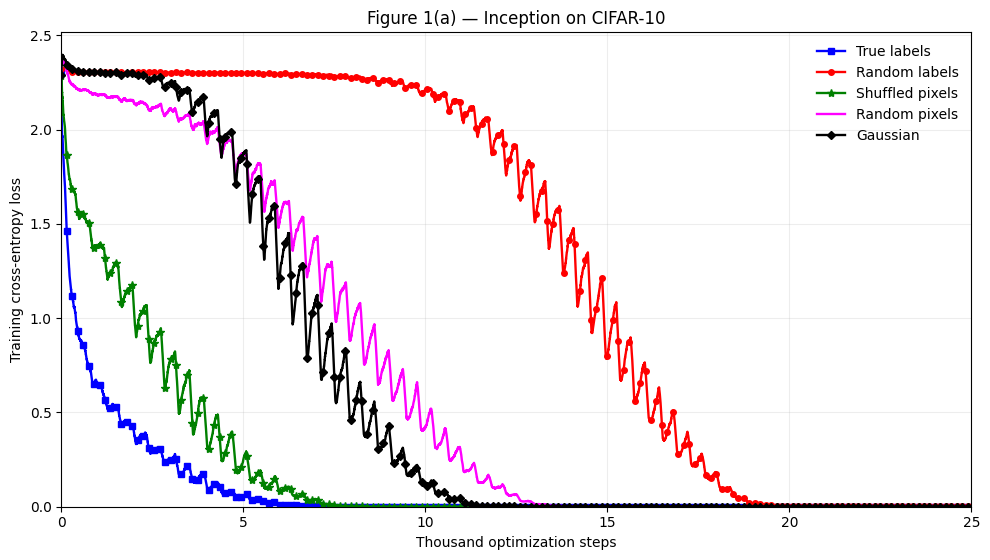

Figure 1(a): 5/5 curves


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Optional: set to your absolute folder path if auto-detection fails.
RESULTS_ROOT = None

def find_results():
    if RESULTS_ROOT is not None:
        candidate = Path(RESULTS_ROOT).expanduser().resolve()
        if not candidate.is_dir():
            raise FileNotFoundError(candidate)
        return candidate
    cwd = Path.cwd().resolve()
    candidates = [
        cwd / 'results' / 'figure1',
        cwd.parent / 'results' / 'figure1',
        cwd / 'paper1-generalization' / 'results' / 'figure1',
    ]
    for candidate in candidates:
        if candidate.is_dir():
            return candidate
    raise FileNotFoundError('Could not locate results/figure1. Set RESULTS_ROOT above.')

root = find_results()
print('Reading:', root)

CONDITIONS = [
    ('True labels', 'label_corruption/inception/p000/steps.csv', 'blue', 's'),
    ('Random labels', 'label_corruption/inception/p100/steps.csv', 'red', 'o'),
    ('Shuffled pixels', 'input_randomization/inception/shared_shuffle/steps.csv', 'green', '*'),
    ('Random pixels', 'input_randomization/inception/independent_shuffle/steps.csv', 'magenta', None),
    ('Gaussian', 'input_randomization/inception/gaussian/steps.csv', 'black', 'D'),
]
MAX_STEPS = 25_000
SMOOTHING_STEPS = 100

def trailing_mean(values, window):
    if window <= 1:
        return values.copy()
    return pd.Series(values).rolling(window, min_periods=1).mean().to_numpy()

fig, ax = plt.subplots(figsize=(10, 5.7))
count = 0
for label, relative_path, color, marker in CONDITIONS:
    path = root / relative_path
    if not path.is_file():
        print('MISSING:', label, '→', relative_path)
        continue
    d = pd.read_csv(path, usecols=['step', 'batch_train_ce'])
    d = d[(d.step <= MAX_STEPS) & np.isfinite(d.batch_train_ce)].sort_values('step')
    d = d.drop_duplicates('step', keep='last')
    if d.empty:
        print('EMPTY:', label)
        continue
    ax.plot(d.step / 1000, trailing_mean(d.batch_train_ce.to_numpy(), SMOOTHING_STEPS),
            label=label, color=color, linewidth=1.7, marker=marker,
            markersize=6 if marker == '*' else 4,
            markevery=150 if marker else None)
    print(f'{label}: {len(d):,} steps; last step {int(d.step.iloc[-1]):,}')
    count += 1
if not count:
    plt.close(fig)
    raise ValueError('No Inception training curves found.')
ax.set(xlabel='Thousand optimization steps', ylabel='Training cross-entropy loss',
       title='Figure 1(a) — Inception on CIFAR-10')
ax.set_xlim(0, MAX_STEPS / 1000)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.22)
ax.legend(frameon=False)
fig.tight_layout()
display(fig)
plt.close(fig)
print(f'Figure 1(a): {count}/5 curves')

## Figure 1(b) — Relative convergence time (1% criterion)

Recompute the earliest pair of consecutive qualifying epochs from each `epochs.csv`. Divide each convergence step by that model’s own baseline step at 0% corruption. This is a sensitivity analysis, not a replacement of the Phase 3 results.


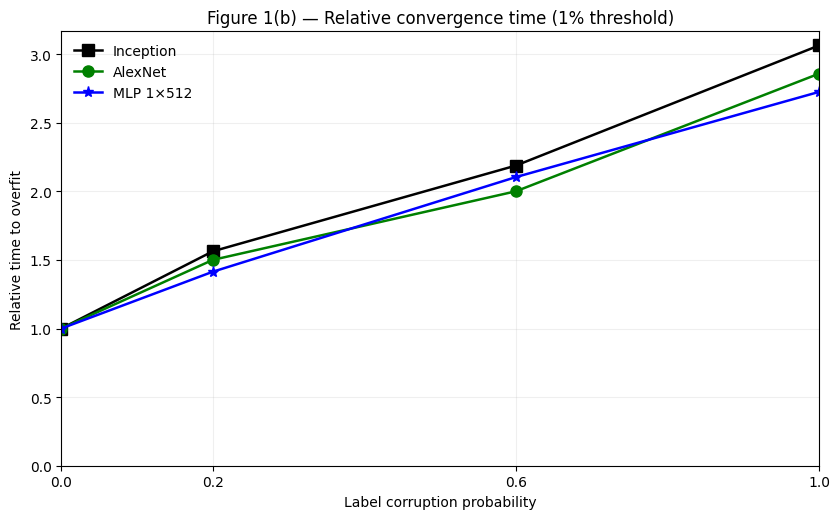

Phase 4 sensitivity analysis: 1% training-error threshold for two consecutive epochs
    model   p  convergence_step  train_error_pct  test_error_pct test_measurement
inception 0.0              6256            0.038           14.02   at convergence
inception 0.2              9775            0.108           30.15   at convergence
inception 0.6             13685            0.008           63.07   at convergence
inception 1.0             19159            0.044           90.20   at convergence
  alexnet 0.0              5474            0.456           23.44   at convergence
  alexnet 0.2              8211            0.250           35.78   at convergence
  alexnet 0.6             10948            0.298           65.18   at convergence
  alexnet 1.0             15640            0.340           89.66   at convergence
      mlp 0.0             11339            0.500           47.96   at convergence
      mlp 0.2             16031            0.870           58.27   at convergence
      mlp 0.6

In [2]:
MODELS = [('inception', 'Inception'), ('alexnet', 'AlexNet'), ('mlp', 'MLP 1×512')]
PROBABILITIES = [0.0, 0.2, 0.6, 1.0]
STYLES = {
    'inception': dict(color='black', marker='s'),
    'alexnet': dict(color='green', marker='o'),
    'mlp': dict(color='blue', marker='*'),
}

CONVERGENCE_THRESHOLD = 0.01  # fraction = 1% training classification error
CONVERGENCE_PATIENCE = 2

def load_experiment_summary(root):
    records = []
    for model, label in MODELS:
        for p in PROBABILITIES:
            folder = root / 'label_corruption' / model / f'p{round(p * 100):03d}'
            epochs_path = folder / 'epochs.csv'
            if not epochs_path.is_file():
                print('MISSING:', model, p)
                continue
            try:
                epochs = pd.read_csv(epochs_path).sort_values('step').drop_duplicates('step', keep='last')
                if epochs.empty:
                    raise ValueError('epochs.csv is empty')
                required = {'step', 'train_error', 'test_error'}
                if not required.issubset(epochs.columns):
                    raise ValueError(f'Missing columns {required - set(epochs.columns)}')
                # train_error is stored as a fraction in epochs.csv (0.01 = 1%).
                good = (epochs.train_error <= CONVERGENCE_THRESHOLD).to_numpy()
                qualifying_row = None
                for j in range(CONVERGENCE_PATIENCE - 1, len(good)):
                    if good[j - CONVERGENCE_PATIENCE + 1:j + 1].all():
                        qualifying_row = j
                        break
                converged = qualifying_row is not None
                endpoint = epochs.iloc[qualifying_row] if converged else epochs.iloc[-1]
                step = int(endpoint.step) if converged else None
                records.append(dict(
                    model=model, label=label, p=p, convergence_step=step,
                    test_error_pct=100 * float(endpoint.test_error),
                    train_error_pct=100 * float(endpoint.train_error),
                    test_measurement='at convergence' if converged else 'last available epoch',
                    endpoint_step=int(endpoint.step), final_logged_step=int(epochs.step.iloc[-1]),
                ))
            except Exception as exc:
                print('INVALID:', folder, str(exc))
    return pd.DataFrame(records)

df = load_experiment_summary(root)
if df.empty:
    raise ValueError('No label corruption results found.')

fig, ax = plt.subplots(figsize=(8.5, 5.3))
for model, label in MODELS:
    subset = df[df.model == model].set_index('p').sort_index()
    if 0.0 not in subset.index:
        print('MISSING BASELINE:', label)
        continue
    baseline = subset.loc[0.0, 'convergence_step']
    if pd.isna(baseline) or baseline <= 0:
        print('BASELINE DID NOT CONVERGE:', label)
        continue
    valid = subset.dropna(subset=['convergence_step'])
    if valid.empty:
        continue
    ax.plot(valid.index.to_numpy(), valid.convergence_step.to_numpy() / baseline,
            label=label, linewidth=1.8, markersize=8, **STYLES[model])
    missing = subset[subset.convergence_step.isna()]
    if not missing.empty:
        print(f'{label}: convergence not reached at p={missing.index.to_list()}')
ax.set(xlabel='Label corruption probability', ylabel='Relative time to overfit',
       title='Figure 1(b) — Relative convergence time (1% threshold)')
ax.set_xlim(0, 1)
ax.set_xticks(PROBABILITIES)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
display(fig)
plt.close(fig)
print('Phase 4 sensitivity analysis: 1% training-error threshold for two consecutive epochs')
print(df[['model','p','convergence_step','train_error_pct','test_error_pct','test_measurement']].to_string(index=False))


## Figure 1(c) — Test error at the 1% convergence point

Test error is taken at the second of the two qualifying epochs; unconverged runs, if any, use the final logged epoch and are marked with open circles.


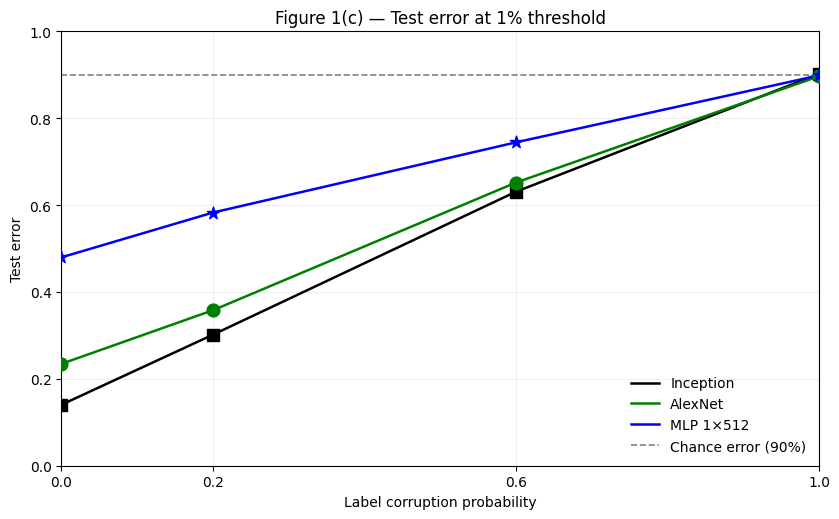

In [3]:
if 'df' not in globals() or df.empty:
    raise ValueError('Run the Figure 1(b) cell first to load the experiment metrics.')

fig, ax = plt.subplots(figsize=(8.5, 5.3))
for model, label in MODELS:
    subset = df[df.model == model].sort_values('p')
    if subset.empty:
        continue
    style = STYLES[model]
    ax.plot(subset.p, subset.test_error_pct / 100,
            label=label, color=style['color'], linewidth=1.8)
    converged = subset[subset.test_measurement == 'at convergence']
    unfinished = subset[subset.test_measurement != 'at convergence']
    if not converged.empty:
        ax.scatter(converged.p, converged.test_error_pct / 100,
                   color=style['color'], marker=style['marker'], s=85, zorder=4)
    if not unfinished.empty:
        ax.scatter(unfinished.p, unfinished.test_error_pct / 100,
                   facecolors='none', edgecolors=style['color'], marker='o',
                   s=95, linewidths=1.8, zorder=5)
        print(f'{label}: open circles are final-epoch estimates at p={unfinished.p.to_list()}')
ax.axhline(0.9, color='gray', linestyle='--', linewidth=1.2,
           label='Chance error (90%)')
ax.set(xlabel='Label corruption probability', ylabel='Test error',
       title='Figure 1(c) — Test error at 1% threshold')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xticks(PROBABILITIES)
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
display(fig)
plt.close(fig)